# 01 - Exploratory Data Analysis

**Goal:** understand the transaction dataset *before* modeling: data quality, targets, which columns carry signal,
how merchant names behave, and what ceiling to expect from a name-based approach.

**Questions we want to answer**
1. Are the data and labels clean (empty values, case variants, duplicates)?
2. How do `minor_category` and `major_category` relate? (strict hierarchy?)
3. Are `title` and `merchant_name` redundant?
4. Which columns are constant, near-constant, identifiers, or leakage risks?
5. Can `refund` / `atm` be identified from simple signals (amount sign, entry method)?
6. How messy are merchant names, and how much does normalization (incl. fuzzy matching) help?
7. How ambiguous are merchants (same name, several classes)? What is the ceiling of a pure name lookup?

*No train/test split exists yet. This notebook only describes the full dataset; nothing here is used to fit a model.*

## 1. Setup and loading

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.sparse.csgraph import connected_components
from scipy.stats import chi2_contingency
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("../data/raw/transaction-dataset-1.csv")

In [2]:
# keep_default_na=False: empty strings stay as '' (we want to SEE them, not have pandas silently turn them into NaN)
# ids are read as strings: they are identifiers, not numbers.
df = pd.read_csv(
    DATA_PATH,
    keep_default_na=False,
    dtype={"transaction_id": str, "member_id": str, "ref_id": str, "merchant_id": str},
)
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)
print(f"shape: {df.shape}")
df.head()

shape: (8121, 19)


,transaction_id,ref_id,created_at,member_id,member_name,merchant_id,merchant_name,title,amount_value,amount_currency,fees,card_type,card_name,digitalization_type,merchant_pan_entry_method,pfm_recurring_frequency,status,major_category,minor_category
0,10022027,980ebfdf5da81298,2026-04-28 11:45:21+00:00,49428661,Emma Mercier,M6533702170,MAC DONALD S,MAC DONALD S,-22.18,EUR,0,lydia-card,Carte sans contact basique,apple_pay,CHIP_CONTACTLESS,,completed,restaurants_bars_cafes,restaurants
1,10003553,c5dded2c77c63706,2026-03-16 19:51:25+00:00,51617680,Marine Durand,M8593525314,CARREFOURMARKET,CARREFOURMARKET,-6.83,EUR,0,lydia-card,Carte Lydia bleue,none,CHIP_CONTACTLESS,,completed,groceries,supermarkets
2,10028220,6dbc2a2ce0fef4c0,2026-03-28 12:51:29+00:00,79696025,Sarah Rousseau,M2159707263,TOTAL,TOTAL,-53.26,EUR,0,lydia-card,Carte noire,none,CHIP_CONTACTLESS,,completed,transportation,tolls_gas_stations
3,10005013,e8bdb4b0fd67f7d9,2026-06-10 15:32:48+00:00,48260510,Alexandre Rousseau,M2434486874,PROXI,PROXI,-6.61,EUR,0,lydia-card,Carte Lydia bleue,google_pay,CHIP_CONTACTLESS,,completed,groceries,supermarkets
4,10027189,6f5c542a8620e54e,2026-03-27 18:58:30+00:00,53258988,Lucas André,M5169624957,BETCLIC,BETCLIC,-68.04,EUR,0,lydia-card,Carte noire,none,MANUAL,,completed,entertainment,betting


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8121 entries, 0 to 8120
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype              
---  ------                     --------------  -----              
 0   transaction_id             8121 non-null   str                
 1   ref_id                     8121 non-null   str                
 2   created_at                 8121 non-null   datetime64[us, UTC]
 3   member_id                  8121 non-null   str                
 4   member_name                8121 non-null   str                
 5   merchant_id                8121 non-null   str                
 6   merchant_name              8121 non-null   str                
 7   title                      8121 non-null   str                
 8   amount_value               8121 non-null   float64            
 9   amount_currency            8121 non-null   str                
 10  fees                       8121 non-null   int64              
 11  card_type      

In [4]:
print("date range:", df["created_at"].min(), "->", df["created_at"].max())
print("span (days):", (df["created_at"].max() - df["created_at"].min()).days)
print("NaN cells:", int(df.isna().sum().sum()), "(none expected, empties are '' strings)")

date range: 2026-03-13 00:03:44+00:00 -> 2026-06-10 23:59:49+00:00
span (days): 89
NaN cells: 0 (none expected, empties are '' strings)


## 2. Column audit

Per column: type, cardinality, number of empty strings, and the most frequent value with its share.
This surfaces constant / near-constant columns and identifiers at a glance.

In [5]:
# check what is in value
df[["amount_value"]].value_counts()

amount_value
-20.00          113
-10.00          107
-6.99            88
-9.99            79
-7.99            78
               ... 
-1482.27          1
-34.29            1
-67.44            1
-45.61            1
-20.72            1
Name: count, Length: 3588, dtype: int64

In [6]:
# check what is in card name
df[["card_name"]].value_counts()

card_name                       
Carte standard                      1070
Carte noire                         1004
Carte Lydia bleue                    953
Carte basique                        904
Carte sans contact basique           879
Carte sans contact bleue             617
Carte classique                      455
Carte virtuelle                      369
Carte sans contact noire             237
Carte aux couleurs de Paris 2024     178
Carte abonnements                    154
Carte d'abonnements                  151
Carte sans contact classique         146
Contactless card classic             129
Carte 1 paiement                     112
Carte Lydia noire                     89
Carte Internet bleue                  86
Classic card                          63
Basic card                            58
Standard card                         57
Subscriptions card                    53
Carte virtuelle standard              53
Contactless blue card                 46
Virtual card            

In [7]:
# check what is in card name
df[["digitalization_type"]].value_counts()

digitalization_type
apple_pay              3575
none                   3298
google_pay              650
UNKNOWN                 214
samsung_pay             110
UBER                     76
PAYPAL                   76
GOOGLE_PAYMENTS_INC      44
SPOTIFY                  39
MICROSOFT_NETWORK        10
NETFLIX                  10
TAXIFY                    9
STRIPE                    6
DEEZER                    4
Name: count, dtype: int64

In [8]:
def top_value(s):
    vc = s.value_counts()
    return vc.index[0], vc.iloc[0] / len(s)

rows = []
for c in df.columns:
    tv, share = top_value(df[c])
    rows.append({
        "column": c,
        "dtype": str(df[c].dtype),
        "n_unique": df[c].nunique(),
        "n_empty": int((df[c].astype(str).str.strip() == "").sum()),
        "top_value": str(tv)[:30],
        "top_share": round(share, 3),
    })
audit = pd.DataFrame(rows).set_index("column")
audit

,dtype,n_unique,n_empty,top_value,top_share
column,,,,,
transaction_id,str,8121,0,10022027,0.000
ref_id,str,8001,0,4bc2508f2ede0679,0.000
created_at,"datetime64[us, UTC]",7999,0,2026-04-16 07:50:36+00:00,0.000
member_id,str,2395,0,79696025,0.001
member_name,str,836,0,Romain Durand,0.004
merchant_id,str,2789,0,M9617909120,0.018
merchant_name,str,960,113,APPLE.COM/BILL,0.137
title,str,960,0,APPLE.COM/BILL,0.137
amount_value,float64,3588,0,-20.0,0.014


> 📝 **NOTE (jafar):** transaction_id, to remove. ref_if, no info. Created_at, add features like day of week, day of month. member_id, member_name to remove (likely not complying with law, to check in france, at any case, not carrying any info). merchant_id, merchant_name, to check why merchant id has high cardinality while merchant name has low? amount, to check, if tree method, leave it, tree will handle it. currency to remove. fees to remove. card_type to remove. 

Reading the table:
- `card_type` and `amount_currency` have a single value: **constant, zero information**.
- `fees` is 0 for almost every row; `pfm_recurring_frequency` is empty for almost every row. Near-constant, but the rare
  non-default values could still be informative: to be checked against the target below.
- `transaction_id`, `ref_id`, `member_id`, `member_name`, `merchant_id` are identifiers (high cardinality).

## 3. Targets
### 3.1 Class distributions

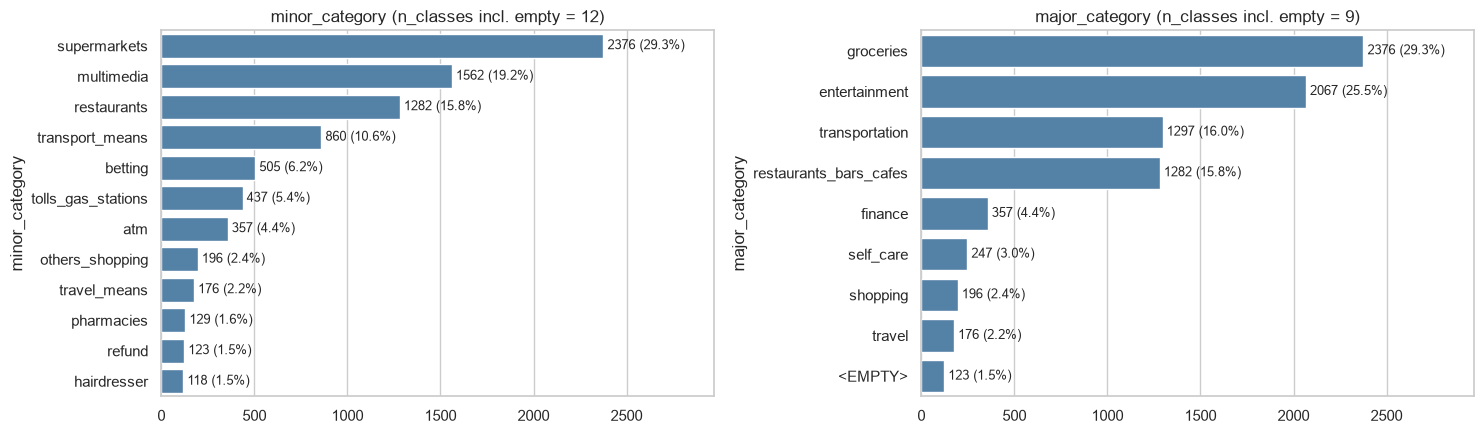

imbalance ratio minor (max/min): 20.1x


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ["minor_category", "major_category"]):
    vc = df[col].replace("", "<EMPTY>").value_counts()
    sns.barplot(x=vc.values, y=vc.index, ax=ax, color="steelblue")
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v} ({v / len(df):.1%})", va="center", fontsize=9)
    ax.set_title(f"{col} (n_classes incl. empty = {len(vc)})")
    ax.set_xlim(0, vc.max() * 1.25)
plt.tight_layout()
plt.show()

vc = df["minor_category"].value_counts()
print(f"imbalance ratio minor (max/min): {vc.max() / vc.min():.1f}x")

### 3.2 Case / whitespace variants in labels

In [10]:
for col in ["minor_category", "major_category"]:
    raw = df[col].nunique()
    norm = df[col].str.strip().str.lower().nunique()
    print(f"{col}: raw unique = {raw}, after strip+lower = {norm}")

minor_category: raw unique = 12, after strip+lower = 12
major_category: raw unique = 9, after strip+lower = 9


### 3.3 Minor to major mapping
Is it a strict hierarchy (each minor class belongs to exactly one major class)?

In [11]:
ct = pd.crosstab(df["minor_category"], df["major_category"].replace("", "<EMPTY>"))
display(ct)

mapping = (
    df.groupby("minor_category")["major_category"]
    .agg(lambda s: sorted(s.replace("", "<EMPTY>").unique()))
)
print("\nmajor classes per minor class (should be exactly one each):")
display(mapping.to_frame("majors"))
print("Number of minor classes mapped to more than one major:", int((mapping.str.len() > 1).sum()))

major_category,<EMPTY>,entertainment,finance,groceries,restaurants_bars_cafes,self_care,shopping,transportation,travel
minor_category,,,,,,,,,
atm,0,0,357,0,0,0,0,0,0
betting,0,505,0,0,0,0,0,0,0
hairdresser,0,0,0,0,0,118,0,0,0
multimedia,0,1562,0,0,0,0,0,0,0
others_shopping,0,0,0,0,0,0,196,0,0
pharmacies,0,0,0,0,0,129,0,0,0
refund,123,0,0,0,0,0,0,0,0
restaurants,0,0,0,0,1282,0,0,0,0
supermarkets,0,0,0,2376,0,0,0,0,0



major classes per minor class (should be exactly one each):


,majors
minor_category,
atm,[finance]
betting,[entertainment]
hairdresser,[self_care]
multimedia,[entertainment]
others_shopping,[shopping]
pharmacies,[self_care]
refund,[<EMPTY>]
restaurants,[restaurants_bars_cafes]
supermarkets,[groceries]


Number of minor classes mapped to more than one major: 0


In [12]:
empty_major = df[df["major_category"] == ""]
print("rows with empty major_category:", len(empty_major))
print("their minor_category:", empty_major["minor_category"].value_counts().to_dict())
print("their status:", empty_major["status"].value_counts().to_dict())
print("rows with minor == 'refund':", int((df["minor_category"] == "refund").sum()))

rows with empty major_category: 123
their minor_category: {'refund': 123}
their status: {'refunded': 123}
rows with minor == 'refund': 123


In [13]:
df["status"].value_counts()

status
completed    7998
refunded      123
Name: count, dtype: int64

## 4. `title` vs `merchant_name`

In [14]:
diff = df[df["title"] != df["merchant_name"]]
print(f"rows where title != merchant_name: {len(diff)} ({len(diff) / len(df):.2%})")
print("differs even after strip+lower:", int((df['title'].str.strip().str.lower() != df['merchant_name'].str.strip().str.lower()).sum()))
print("\nminor_category of those rows:", diff["minor_category"].value_counts().to_dict())
print("merchant_name values:", diff["merchant_name"].value_counts().head(5).to_dict())
print("title values:", diff["title"].value_counts().head(5).to_dict())

rows where title != merchant_name: 113 (1.39%)
differs even after strip+lower: 113

minor_category of those rows: {'atm': 109, 'transport_means': 4}
merchant_name values: {'': 113}
title values: {'RETRAIT DAB': 113}


In [15]:
# the 4 transport_means rows: what are they?
display(diff[diff["minor_category"] != "atm"][["merchant_name", "title", "amount_value", "merchant_pan_entry_method", "minor_category"]])
# are there ATM rows where merchant_name is NOT empty?
atm = df[df["minor_category"] == "atm"]
print("ATM rows:", len(atm), "| with empty merchant_name:", int((atm["merchant_name"] == "").sum()))
print("ATM merchant_name (non-empty) top:", atm.loc[atm["merchant_name"] != "", "merchant_name"].value_counts().head(5).to_dict())

,merchant_name,title,amount_value,merchant_pan_entry_method,minor_category
1154,,RETRAIT DAB,-40.0,CHIP,transport_means
1571,,RETRAIT DAB,-100.0,CHIP,transport_means
2043,,RETRAIT DAB,-310.0,CHIP,transport_means
7489,,RETRAIT DAB,-100.0,CHIP,transport_means


ATM rows: 357 | with empty merchant_name: 109
ATM merchant_name (non-empty) top: {'LA BANQUE POSTALE': 108, 'CASH SERVICES': 81, 'LA SOCIETE GENERALE': 15, 'LOOMIS FRANCE PARIS': 4, '497208300020536': 2}


We will build a single text field: `merchant_name`, falling back to `title` when `merchant_name` is empty. We also keep a
boolean "merchant_name is empty" feature, since an empty name plus `RETRAIT DAB` is a very strong ATM signal.

In [16]:
df["text_raw"] = np.where(df["merchant_name"].str.strip() != "", df["merchant_name"], df["title"])
print("rows with empty text after fallback:", int((df["text_raw"].str.strip() == "").sum()))

rows with empty text after fallback: 0


## 5. Amount
### 5.1 Sign vs class (can `refund` / `atm` be identified from the sign?)

In [17]:
df["sign"] = np.select([df["amount_value"] > 0, df["amount_value"] < 0], ["positive", "negative"], default="zero")
display(pd.crosstab(df["minor_category"], df["sign"]))

print("\nstatus vs sign:")
display(pd.crosstab(df["status"], df["sign"]))
print("\nstatus vs minor == refund:")
display(pd.crosstab(df["status"], df["minor_category"] == "refund"))

sign,negative,positive,zero
minor_category,,,
atm,352,0,5
betting,505,0,0
hairdresser,118,0,0
multimedia,1562,0,0
others_shopping,196,0,0
pharmacies,129,0,0
refund,0,123,0
restaurants,1282,0,0
supermarkets,2376,0,0



status vs sign:


sign,negative,positive,zero
status,,,
completed,7993,0,5
refunded,0,123,0



status vs minor == refund:


minor_category,False,True
status,,
completed,7998,0
refunded,0,123


In [18]:
# Note: -0.0 shows up as 'zero' above; those rows:
display(df[df["amount_value"] == 0][["merchant_name", "title", "amount_value", "status", "minor_category", "merchant_pan_entry_method"]])

,merchant_name,title,amount_value,status,minor_category,merchant_pan_entry_method
394,,RETRAIT DAB,-0.0,completed,atm,CHIP
542,,RETRAIT DAB,-0.0,completed,atm,CHIP
5211,LA BANQUE POSTALE,LA BANQUE POSTALE,-0.0,completed,atm,CHIP
7763,,RETRAIT DAB,-0.0,completed,atm,CHIP
8042,,RETRAIT DAB,-0.0,completed,atm,CHIP


### 5.2 Amount distributions by class
Absolute amount on a log scale (amounts span several orders of magnitude).

In [19]:
order

NameError: name 'order' is not defined

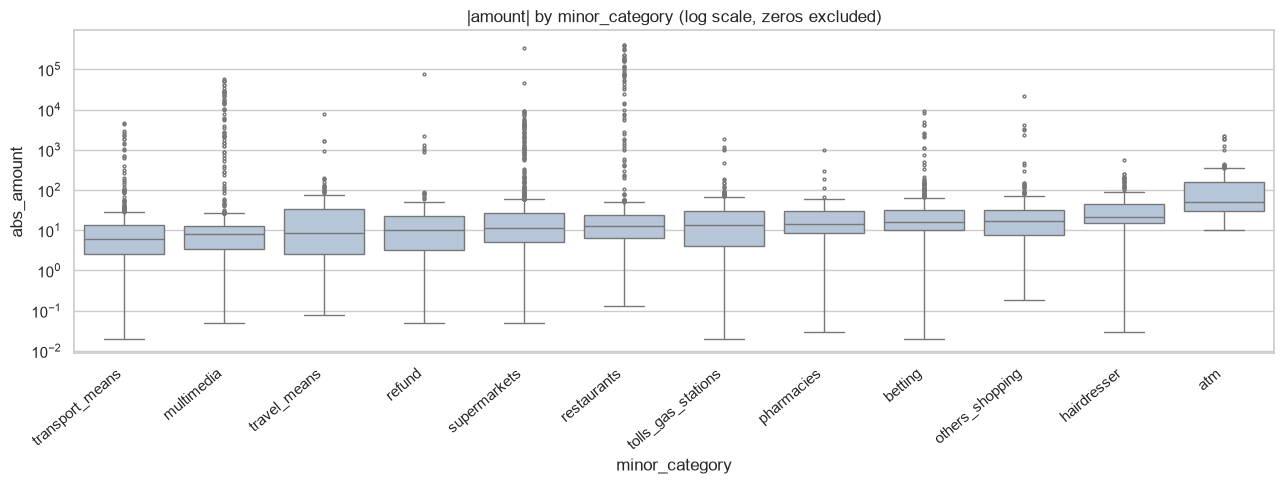

,count,mean,std,min,5%,50%,95%,max
minor_category,,,,,,,,
transport_means,860.0,46.09,302.96,0.02,1.05,5.99,40.00,4575.46
multimedia,1562.0,496.39,3881.37,0.05,0.93,7.99,27.43,56475.30
travel_means,176.0,92.53,615.41,0.08,0.76,8.56,128.06,7806.15
refund,123.0,686.96,6860.77,0.05,0.67,10.00,86.48,76098.48
supermarkets,2376.0,255.84,6880.18,0.05,1.55,11.66,84.10,330978.29
restaurants,1282.0,4186.04,30464.34,0.13,2.31,12.76,57.40,399180.56
tolls_gas_stations,437.0,35.75,127.06,0.02,1.25,13.44,82.52,1800.93
pharmacies,129.0,30.16,90.31,0.03,1.83,14.44,58.07,975.77
betting,505.0,112.20,667.16,0.02,2.63,15.88,144.16,9068.38


In [20]:
df["abs_amount"] = df["amount_value"].abs()
order = df.groupby("minor_category")["abs_amount"].median().sort_values().index

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=df[df["abs_amount"] > 0], x="minor_category", y="abs_amount", order=order, ax=ax, color="lightsteelblue", fliersize=2)
ax.set_yscale("log")
ax.set_title("|amount| by minor_category (log scale, zeros excluded)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

display(df.groupby("minor_category")["abs_amount"].describe(percentiles=[0.05, 0.5, 0.95]).round(2).loc[order])

In [21]:
print("Largest absolute amounts:")
display(df.nlargest(8, "abs_amount")[["merchant_name", "amount_value", "minor_category", "status", "merchant_pan_entry_method"]])

Largest absolute amounts:


,merchant_name,amount_value,minor_category,status,merchant_pan_entry_method
2141,MC DONALD S,-399180.56,restaurants,completed,CHIP_CONTACTLESS
7773,VIRAGE,-396717.83,restaurants,completed,CHIP_CONTACTLESS
7120,MC DONALD'S,-370324.15,restaurants,completed,CHIP_CONTACTLESS
1104,Burger King,-330978.29,supermarkets,completed,CHIP_CONTACTLESS
286,BUFFALO GRILL,-322254.97,restaurants,completed,CHIP_CONTACTLESS
3157,BUFFALO GRILL,-322254.97,restaurants,completed,CHIP_CONTACTLESS
1486,LS SEPT LIEUX,-307066.76,restaurants,completed,CHIP_CONTACTLESS
2211,T CHAMPIONS BURGER GIRA 5,-226788.68,restaurants,completed,CHIP_CONTACTLESS


In [22]:
for thr in (1_000, 10_000, 100_000):
    sub = df[df["abs_amount"] > thr]
    print(f"|amount| > {thr:>7,}: {len(sub):4d} rows | by class: {sub['minor_category'].value_counts().to_dict()}")

|amount| >   1,000:  188 rows | by class: {'supermarkets': 49, 'restaurants': 49, 'multimedia': 45, 'betting': 11, 'transport_means': 11, 'atm': 6, 'refund': 5, 'others_shopping': 5, 'tolls_gas_stations': 4, 'travel_means': 3}
|amount| >  10,000:   65 rows | by class: {'restaurants': 36, 'multimedia': 25, 'supermarkets': 2, 'others_shopping': 1, 'refund': 1}
|amount| > 100,000:   21 rows | by class: {'restaurants': 20, 'supermarkets': 1}


Extreme values need a decision at modeling time (log transform, clipping, or trusting tree models to be robust).

## 6. Categorical / technical features vs class

For each feature value, the share of each `minor_category` among its rows, i.e. **P(class | value)**. Row labels include the
number of rows. A feature is useful if rows of this heatmap look *different* from each other (and from the global distribution).

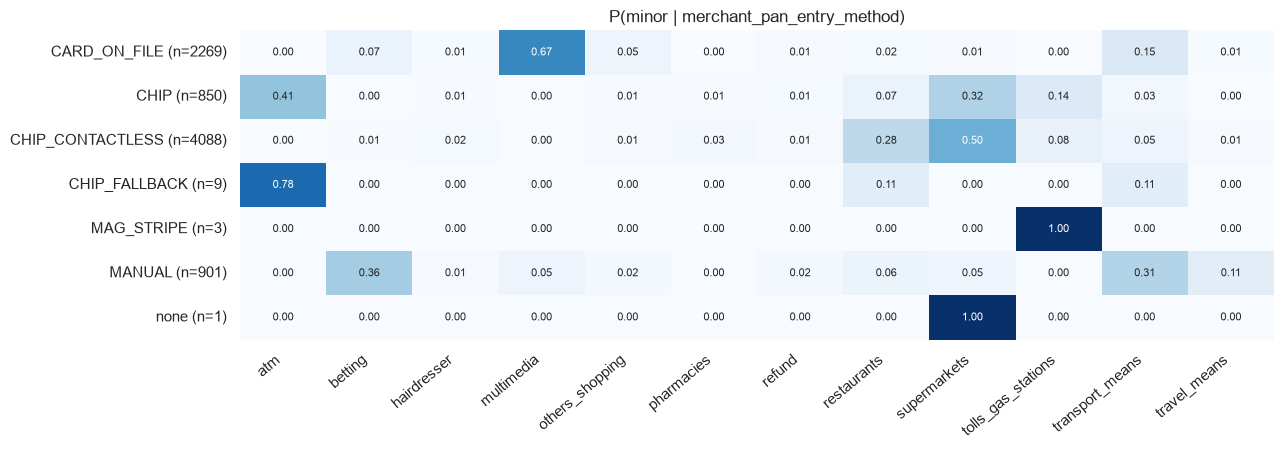

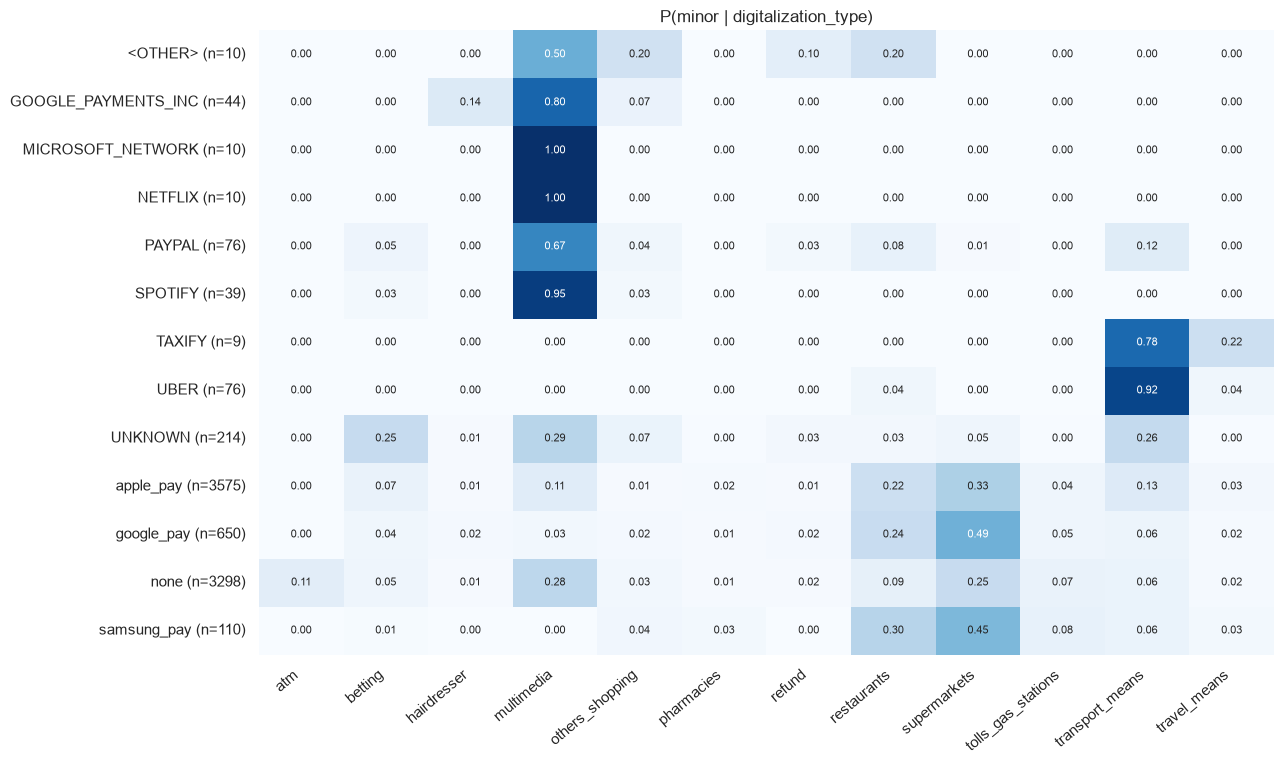

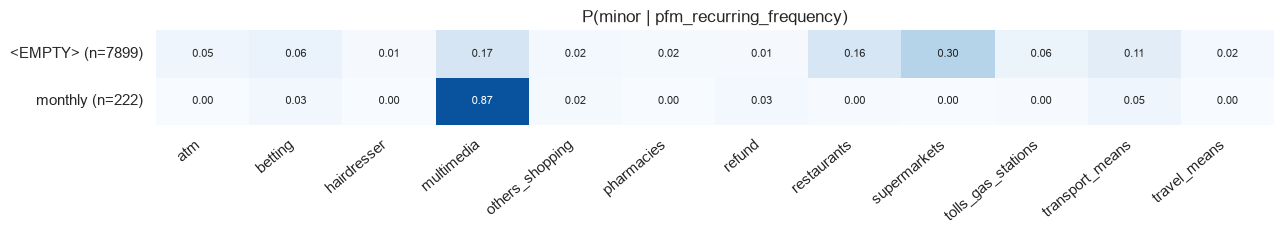

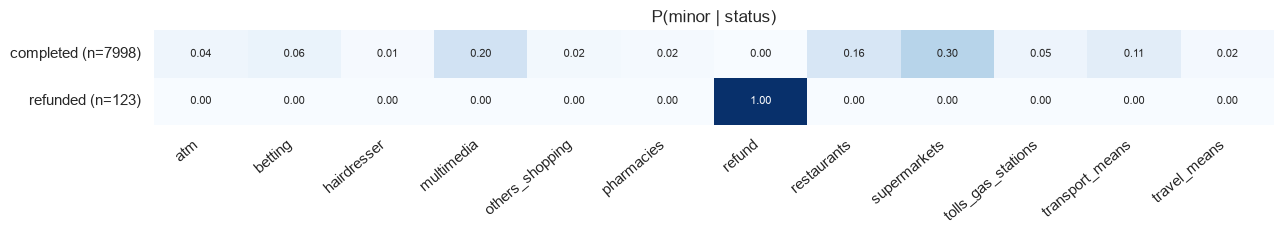

In [23]:
def cond_heatmap(col, top=12, min_rows=1, ax=None, title=None):
    s = df[col].astype(str).replace("", "<EMPTY>")
    keep = s.value_counts().head(top).index
    s = s.where(s.isin(keep), "<OTHER>")
    ct = pd.crosstab(s, df["minor_category"])
    n = ct.sum(axis=1)
    ct = ct.div(n, axis=0)
    ct.index = [f"{i} (n={n[i]})" for i in ct.index]
    ax = ax or plt.gca()
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 8}, vmin=0, vmax=1)
    ax.set_title(title or f"P(minor | {col})")
    ax.set_xlabel("")
    ax.set_ylabel("")

for col in ["merchant_pan_entry_method", "digitalization_type", "pfm_recurring_frequency", "status"]:
    n_rows = df[col].nunique()
    fig, ax = plt.subplots(figsize=(13, max(2.5, 0.45 * n_rows + 1.5)))
    cond_heatmap(col, ax=ax)
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

> 📝 **NOTE (jafar):** categories like chip_fallback, mag_stripe, low accurence, might be safer to remove. Some digitalization type, very strong signal, low accurence. recurring frequency as well. refund, obviously, we saw this already.

In [24]:
print("digitalization_type values:"); print(df["digitalization_type"].value_counts().to_dict())
print("\nmerchant_pan_entry_method values:"); print(df["merchant_pan_entry_method"].value_counts().to_dict())
print("\ncard_name values:"); print(df["card_name"].value_counts().to_dict())

digitalization_type values:
{'apple_pay': 3575, 'none': 3298, 'google_pay': 650, 'UNKNOWN': 214, 'samsung_pay': 110, 'UBER': 76, 'PAYPAL': 76, 'GOOGLE_PAYMENTS_INC': 44, 'SPOTIFY': 39, 'MICROSOFT_NETWORK': 10, 'NETFLIX': 10, 'TAXIFY': 9, 'STRIPE': 6, 'DEEZER': 4}

merchant_pan_entry_method values:
{'CHIP_CONTACTLESS': 4088, 'CARD_ON_FILE': 2269, 'MANUAL': 901, 'CHIP': 850, 'CHIP_FALLBACK': 9, 'MAG_STRIPE': 3, 'none': 1}

card_name values:
{'Carte standard': 1070, 'Carte noire': 1004, 'Carte Lydia bleue': 953, 'Carte basique': 904, 'Carte sans contact basique': 879, 'Carte sans contact bleue': 617, 'Carte classique': 455, 'Carte virtuelle': 369, 'Carte sans contact noire': 237, 'Carte aux couleurs de Paris 2024': 178, 'Carte abonnements': 154, "Carte d'abonnements": 151, 'Carte sans contact classique': 146, 'Contactless card classic': 129, 'Carte 1 paiement': 112, 'Carte Lydia noire': 89, 'Carte Internet bleue': 86, 'Classic card': 63, 'Basic card': 58, 'Standard card': 57, 'Subscriptio

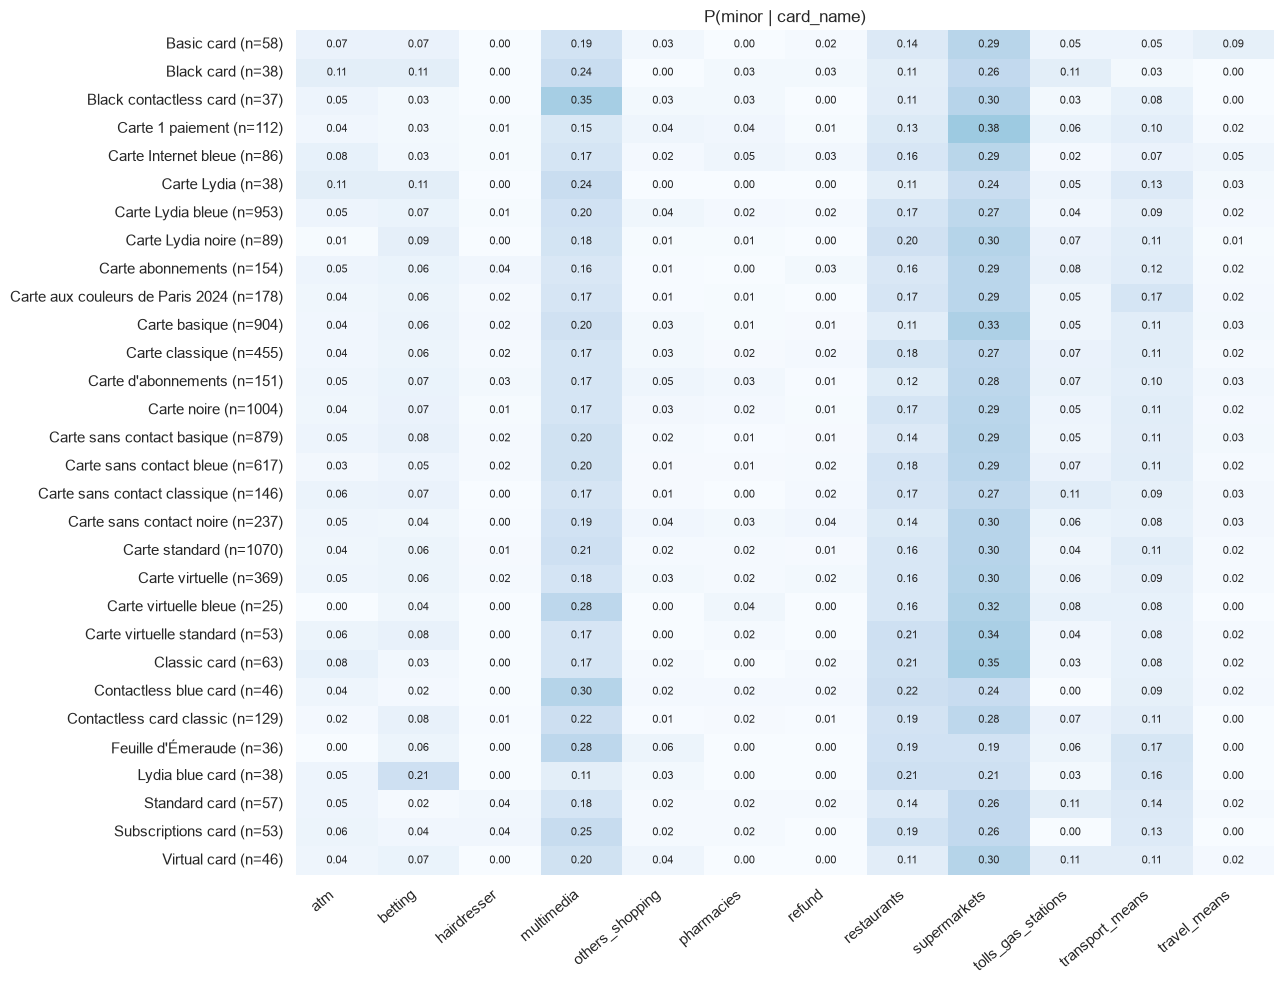

In [25]:
fig, ax = plt.subplots(figsize=(13, 10))
cond_heatmap("card_name", top=30, ax=ax)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

> 📝 **NOTE (jafar):** no super strong correlation here, mostly we see that several classes are much more represented than others

In [26]:
df["fees_nonzero"] = (df["fees"] > 0).astype(int)
display(pd.crosstab(df["fees"], df["minor_category"]))

minor_category,atm,betting,hairdresser,multimedia,others_shopping,pharmacies,refund,restaurants,supermarkets,tolls_gas_stations,transport_means,travel_means
fees,,,,,,,,,,,,
0,355,502,117,1554,195,129,122,1271,2357,432,852,175
100,0,0,0,3,1,0,0,7,7,3,4,0
120,1,1,1,1,0,0,0,1,2,0,0,0
180,0,1,0,2,0,0,0,0,3,1,1,1
240,1,1,0,1,0,0,0,1,3,0,1,0
400,0,0,0,0,0,0,0,1,0,0,1,0
600,0,0,0,0,0,0,1,0,2,1,0,0
4000,0,0,0,1,0,0,0,1,2,0,1,0


> 📝 **NOTE (jafar):** Fees mostly 0, we saw this before

### 6.1 Entry method and ATM

In [27]:
display(pd.crosstab(df["merchant_pan_entry_method"], df["minor_category"] == "atm", rownames=["entry method"], colnames=["is_atm"]))

is_atm,False,True
entry method,,
CARD_ON_FILE,2269,0
CHIP,505,345
CHIP_CONTACTLESS,4083,5
CHIP_FALLBACK,2,7
MAG_STRIPE,3,0
MANUAL,901,0
none,1,0


## 7. Temporal patterns
Timestamps are UTC. We look for a real-world pattern (e.g. restaurants at lunchtime, tolls on weekends) vs. uniform synthetic noise.

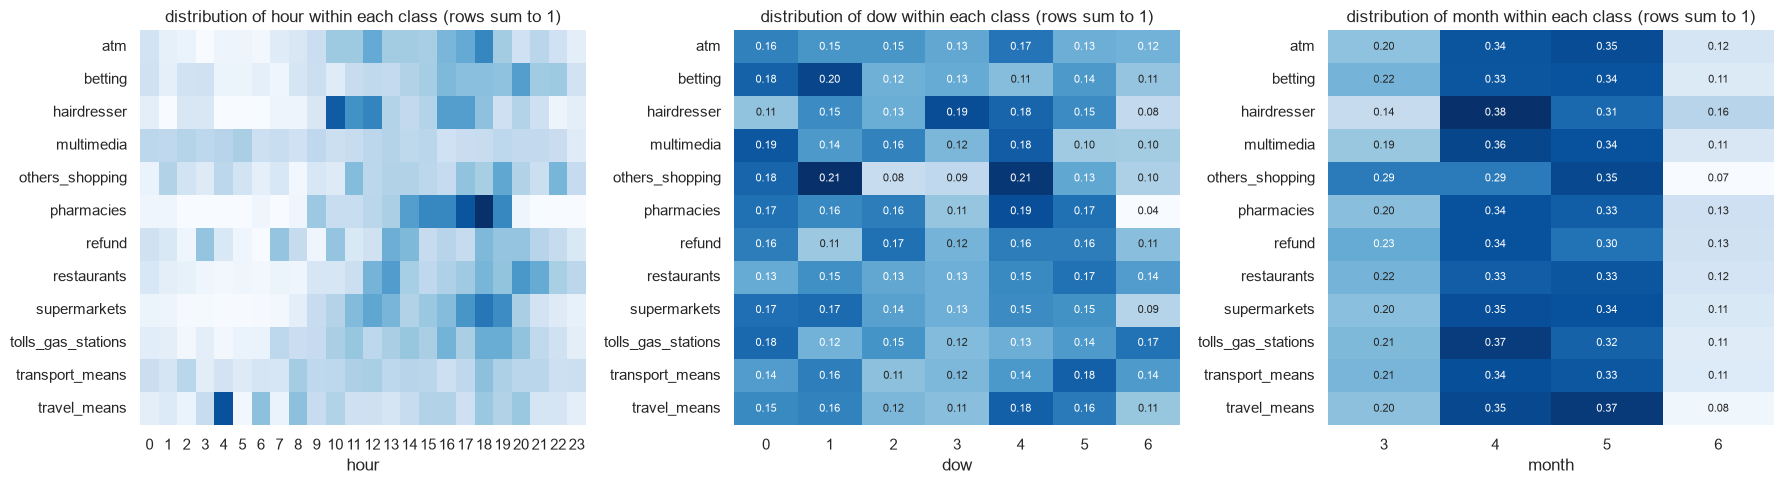

In [28]:
df["hour"] = df["created_at"].dt.hour
df["dow"] = df["created_at"].dt.day_of_week
df["month"] = df["created_at"].dt.month

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["hour", "dow", "month"]):
    ct = pd.crosstab(df["minor_category"], df[col], normalize="index")
    sns.heatmap(ct, cmap="Blues", ax=ax, cbar=False, annot=(col != "hour"), fmt=".2f", annot_kws={"size": 8})
    ax.set_title(f"distribution of {col} within each class (rows sum to 1)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

> 📝 **NOTE (jafar):** We can see some correlation, pharmacies, likely after work, hairdresser in the morning, offers shopping tuesday and friday, etc. First simple features, as we checked here

In [29]:
print("global hour distribution (share of rows):")
display(df["hour"].value_counts(normalize=True).sort_index().round(3).to_frame("share").T)
print("global weekday distribution (0 = Monday):")
display(df["dow"].value_counts(normalize=True).sort_index().round(3).to_frame("share").T)
print("transactions per month:", df["month"].value_counts().sort_index().to_dict())

global hour distribution (share of rows):


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
share,0.026,0.021,0.021,0.018,0.019,0.017,0.015,0.019,0.026,0.038,0.042,0.054,0.066,0.064,0.052,0.054,0.057,0.068,0.083,0.073,0.06,0.046,0.036,0.024


global weekday distribution (0 = Monday):


dow,0,1,2,3,4,5,6
share,0.164,0.16,0.137,0.123,0.158,0.146,0.113


transactions per month: {3: 1665, 4: 2790, 5: 2745, 6: 921}


## 8. Merchant names
### 8.1 Normalization

Raw names are messy: case (`Betclic` / `BETCLIC`), repeated spaces (`UBER   *ONE MEMBERSHIP`), punctuation, accents.
Step one is **deterministic cleaning**: strip accents, lowercase, replace any non-alphanumeric run by a single space, trim.

In [30]:
def normalize_name(s: str) -> str:
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode("ascii").lower()
    s = re.sub(r"[^a-z0-9]+", " ", s).strip()
    return s

df["name_norm"] = df["text_raw"].map(normalize_name)
print("unique raw names       :", df["text_raw"].nunique())
print("unique normalized names:", df["name_norm"].nunique())
print("empty after normalization:", int((df["name_norm"] == "").sum()))

variants = (
    df.groupby("name_norm")["text_raw"].agg(lambda s: sorted(s.unique()))
    .loc[lambda s: s.str.len() > 1]
)
print(f"\n{len(variants)} normalized names have more than one raw spelling. Examples:")
for k, v in variants.head(8).items():
    print(f"  {k!r}: {v}")

unique raw names       : 960
unique normalized names: 930
empty after normalization: 0

28 normalized names have more than one raw spelling. Examples:
  'adobe adobe': ['ADOBE  *ADOBE', 'ADOBE  *Adobe']
  'betclic': ['BETCLIC', 'Betclic']
  'burger king': ['BURGER KING', 'Burger King']
  'carrefour': ['CARREFOUR', 'Carrefour']
  'carrefour city': ['CARREFOUR CITY', 'carrefour city']
  'carrefour market': ['CARREFOUR MARKET', 'carrefour market']
  'disney plus': ['DISNEY PLUS', 'Disney Plus']
  'domino s pizza': ['DOMINO S PIZZA', "DOMINO'S PIZZA"]


### 8.2 Merchant frequency (long tail)

merchants (normalized): 930
seen exactly once     : 374 (40.2% of merchants, 4.6% of rows)
seen <= 5 times       : 776 (83.4% of merchants, 18.7% of rows)
top  10 merchants cover 35.2% of rows
top  25 merchants cover 53.5% of rows
top  50 merchants cover 66.4% of rows
top 100 merchants cover 76.4% of rows


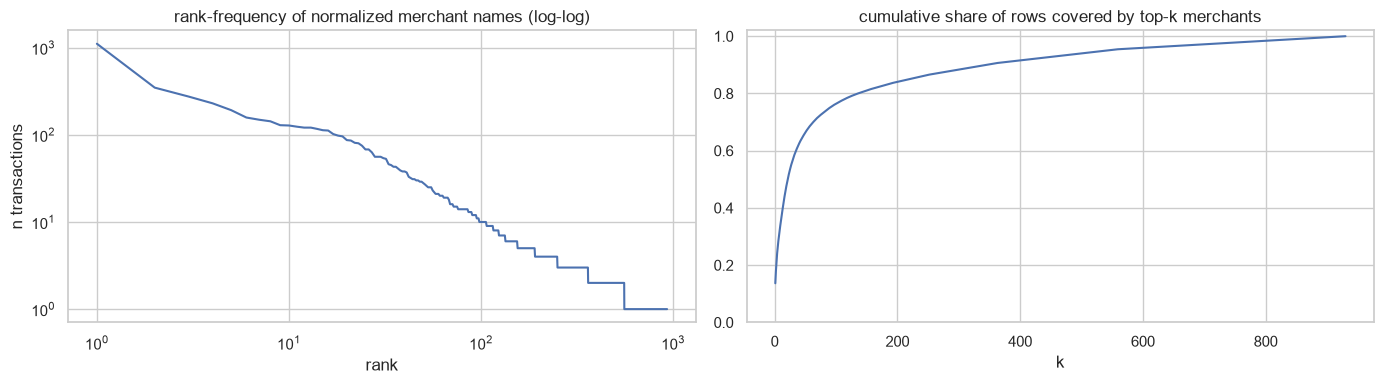


Top 15 merchants:


,n
name_norm,
apple com bill,1110
intermarche,348
carrefour city,275
monoprix,230
mc donald s,192
burger king,158
ubr pending uber com,149
winamax fr,143
carrefour market,129


In [31]:
freq = df["name_norm"].value_counts()
print("merchants (normalized):", len(freq))
print("seen exactly once     :", int((freq == 1).sum()), f"({(freq == 1).mean():.1%} of merchants, {(freq == 1).sum() / len(df):.1%} of rows)")
print("seen <= 5 times       :", int((freq <= 5).sum()), f"({(freq <= 5).mean():.1%} of merchants, {freq[freq <= 5].sum() / len(df):.1%} of rows)")
for k in (10, 25, 50, 100):
    print(f"top {k:>3} merchants cover {freq.head(k).sum() / len(df):.1%} of rows")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1, len(freq) + 1), freq.values)
axes[0].set_yscale("log"); axes[0].set_xscale("log")
axes[0].set_title("rank-frequency of normalized merchant names (log-log)")
axes[0].set_xlabel("rank"); axes[0].set_ylabel("n transactions")
axes[1].plot(np.arange(1, len(freq) + 1), freq.cumsum() / len(df))
axes[1].set_title("cumulative share of rows covered by top-k merchants")
axes[1].set_xlabel("k"); axes[1].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

print("\nTop 15 merchants:")
display(freq.head(15).to_frame("n"))

### 8.3 Fuzzy matching with Levenshtein distance

After deterministic cleaning, some names are still different spellings of the same merchant (e.g. `mcdonald s` vs `mac donald s`).
The **Levenshtein distance** is the minimum number of single-character insertions, deletions and substitutions needed to turn one
string into another. We turn it into a similarity in [0, 1]:

`similarity = 1 - distance / max(len(a), len(b))`

Approach to group names into "canonical merchants":
1. compute the pairwise similarity matrix between all unique normalized names (only ~1k names, cheap),
2. link two names when similarity >= threshold,
3. take connected components of that graph as clusters.

Caveats to measure: edit distance can **merge different merchants** (`area` vs `aprr`, or words that differ by one letter) and
connected components can **chain** (A~B, B~C, so A and C end up together although A and C are not similar).
To pick the threshold we check whether clusters merge names of **different classes**: that is a sign of a bad merge.

In [32]:
print("distance('mcdonald s', 'mac donald s') =", Levenshtein.distance("mcdonald s", "mac donald s"))
print("similarity                              =", round(Levenshtein.normalized_similarity("mcdonald s", "mac donald s"), 3))
print("similarity('total', 'totalenergies')    =", round(Levenshtein.normalized_similarity("total", "totalenergies"), 3))
print("similarity('aprr', 'area')              =", round(Levenshtein.normalized_similarity("aprr", "area"), 3))

distance('mcdonald s', 'mac donald s') = 2
similarity                              = 0.833
similarity('total', 'totalenergies')    = 0.385
similarity('aprr', 'area')              = 0.25


In [33]:
names = sorted(df["name_norm"].unique())
sim = process.cdist(names, names, scorer=Levenshtein.normalized_similarity, dtype=np.float32, workers=-1)
np.fill_diagonal(sim, 0.0)

# majority class of each normalized name (labels are noisy, so compare MAJORITY classes, not all observed classes)
name_major = df.groupby("name_norm")["minor_category"].agg(lambda s: s.value_counts().index[0])

def cluster_names(threshold):
    adj = sim >= threshold
    n_comp, labels = connected_components(adj, directed=False)
    return n_comp, labels

rows = []
for th in (0.70, 0.75, 0.80, 0.85, 0.90, 0.95):
    n_comp, labels = cluster_names(th)
    cl = pd.Series(labels, index=names)
    sizes = cl.value_counts()
    multi = sizes[sizes > 1].index
    # a 'conflicting' cluster merges names whose majority classes differ => a bad merge
    conflicting = sum(name_major[cl[cl == c].index].nunique() > 1 for c in multi)
    rows.append({"threshold": th, "n_clusters": n_comp, "clusters_with_>1_name": len(multi),
                 "names_in_multi_clusters": int(sizes[sizes > 1].sum()), "largest_cluster": int(sizes.max()),
                 "conflicting_clusters(bad merges)": conflicting})
display(pd.DataFrame(rows).set_index("threshold"))

,n_clusters,clusters_with_>1_name,names_in_multi_clusters,largest_cluster,conflicting_clusters(bad merges)
threshold,,,,,
0.70,711,68,287,44,13
0.75,753,56,233,43,8
0.80,825,50,155,16,6
0.85,867,34,97,7,4
0.90,899,24,55,7,3
0.95,929,1,2,2,0


> 📝 **NOTE (jafar):** here would be good to see, when grouping, per cluster, the furthest names in each cluster

In [34]:
TH = 0.85
n_comp, labels = cluster_names(TH)
cl = pd.Series(labels, index=names)
sizes = cl.value_counts()
print(f"threshold {TH}: {len(names)} names -> {n_comp} clusters")
print("\nExample clusters with more than one name:")
shown = 0
for c in sizes[sizes > 1].index:
    members = list(cl[cl == c].index)
    majors = sorted(set(name_major[members]))
    flag = "  <-- CONFLICT" if len(majors) > 1 else ""
    print(f"  [{len(members)} names] {members[:6]}{' ...' if len(members) > 6 else ''}  -> majority classes {majors}{flag}")
    shown += 1
    if shown >= 25:
        break

threshold 0.85: 930 names -> 867 clusters

Example clusters with more than one name:
  [7 names] ['mac donald', 'mac donald s', 'mc donald', 'mc donald s', 'mc donalds', 'mcdonald s'] ...  -> majority classes ['restaurants']
  [7 names] ['pharmacie de l', 'pharmacie de l e', 'pharmacie de la', 'pharmacie des ar', 'pharmacie des ha', 'pharmacie du lac'] ...  -> majority classes ['pharmacies']
  [6 names] ['pharmacie du ce', 'pharmacie du cen', 'pharmacie du cha', 'pharmacie du gra', 'pharmacie du rer', 'pharmacie du rp']  -> majority classes ['pharmacies']
  [5 names] ['intermarche dac', 'intermarche mag', 'intermarche masc', 'intermarche psc', 'intermarche sc']  -> majority classes ['supermarkets', 'tolls_gas_stations']  <-- CONFLICT
  [5 names] ['yego ride 10 min', 'yego ride 13 min', 'yego ride 6 min', 'yego ride 7 min', 'yego ride 9 min']  -> majority classes ['transport_means']
  [4 names] ['mcdonalds 115', 'mcdonalds 1161', 'mcdonalds 1192', 'mcdonalds 1197']  -> majority classes 

#### Furthest names inside each cluster
Connected components can chain (A~B, B~C), so two names in the same cluster may be far apart. For every multi-name cluster
we show the **least similar pair**, sorted from the most dubious cluster. A low similarity (well below the threshold) signals chaining.

In [35]:
rows = []
for c in sizes[sizes > 1].index:
    idx = np.where(labels == c)[0]
    block = sim[np.ix_(idx, idx)].copy()
    np.fill_diagonal(block, 1.0)          # ignore self-similarity
    i, j = np.unravel_index(block.argmin(), block.shape)
    members = [names[k] for k in idx]
    rows.append({
        "cluster": c,
        "n_names": len(idx),
        "furthest_pair_a": names[idx[i]],
        "furthest_pair_b": names[idx[j]],
        "min_similarity": round(float(block[i, j]), 2),
        "n_rows": int(df["name_norm"].isin(members).sum()),
        "majority_classes": sorted(set(name_major[members])),
    })
far = pd.DataFrame(rows).sort_values("min_similarity").reset_index(drop=True)
print(f"threshold {TH}: {len(far)} multi-name clusters; min similarity of the furthest pair, summary:")
print(far["min_similarity"].describe().round(2).to_dict())
print("clusters whose furthest pair is below the threshold (chained):", int((far['min_similarity'] < TH).sum()))
far.head(30)

threshold 0.85: 34 multi-name clusters; min similarity of the furthest pair, summary:
{'count': 34.0, 'mean': 0.87, 'std': 0.07, 'min': 0.6, '25%': 0.83, '50%': 0.88, '75%': 0.93, 'max': 0.95}
clusters whose furthest pair is below the threshold (chained): 9


,cluster,n_names,furthest_pair_a,furthest_pair_b,min_similarity,n_rows,majority_classes
0,472,7,mac donald,mcdonald s,0.60,392,[restaurants]
1,587,7,pharmacie de l e,pharmacie des ar,0.75,11,[pharmacies]
2,192,3,centre e leclerc,ctre leclerc,0.75,35,[supermarkets]
3,698,3,sas capsud exploitation,snc up sud exploitation,0.78,9,[supermarkets]
4,373,5,intermarche mag,intermarche psc,0.80,17,"[supermarkets, tolls_gas_stations]"
5,18,3,497208300020439,497208300020563,0.80,4,[atm]
6,591,6,pharmacie du ce,pharmacie du gra,0.81,9,[pharmacies]
7,316,3,gde pharmacie,grande pharmacie,0.81,12,[pharmacies]
8,160,3,carrefour expr,carrefour express,0.82,66,[supermarkets]
9,493,4,mcdonalds 115,mcdonalds 1161,0.86,11,"[restaurants, transport_means]"


Whether this clustering is actually *useful* will be decided at modeling time (character n-gram TF-IDF may already capture most
of it implicitly). Here we only characterize how much fuzzy duplication exists.

## 9. Ambiguous merchants and the ceiling of a name lookup

Some merchants appear with different classes (`apple.com/bill`, `amazon`, `aprr`...). Pure name matching can never be perfect on those.

In [36]:
per_name = df.groupby("name_norm")["minor_category"].agg(n_classes="nunique", n_rows="size")
amb = per_name[per_name["n_classes"] > 1].sort_values("n_rows", ascending=False)
print(f"normalized names with >1 minor class: {len(amb)} / {len(per_name)} ({len(amb) / len(per_name):.1%} of merchants)")
print(f"rows belonging to those names        : {amb['n_rows'].sum()} / {len(df)} ({amb['n_rows'].sum() / len(df):.1%})")
amb_counts = (
    df[df["name_norm"].isin(amb.index)]
    .groupby(["name_norm", "minor_category"]).size().unstack(fill_value=0)
    .loc[amb.index]
)
display(amb_counts.head(25))

normalized names with >1 minor class: 145 / 930 (15.6% of merchants)
rows belonging to those names        : 5878 / 8121 (72.4%)


minor_category,atm,betting,hairdresser,multimedia,others_shopping,pharmacies,refund,restaurants,supermarkets,tolls_gas_stations,transport_means,travel_means
name_norm,,,,,,,,,,,,
apple com bill,0,26,0,1048,20,0,16,0,0,0,0,0
intermarche,0,0,0,0,6,0,5,13,324,0,0,0
carrefour city,0,0,0,0,4,0,8,5,258,0,0,0
monoprix,0,0,0,0,4,0,3,7,216,0,0,0
mc donald s,0,0,0,0,0,0,0,185,2,0,5,0
burger king,0,0,0,0,0,0,4,145,3,0,6,0
ubr pending uber com,0,0,0,0,0,0,2,7,0,0,138,2
winamax fr,0,132,0,9,0,0,2,0,0,0,0,0
carrefour market,0,0,0,0,0,0,2,0,127,0,0,0


In [37]:
# Ceiling of a PURE name-lookup (in-sample, optimistic): predict the majority class of each normalized name.
def lookup_ceiling(keys):
    g = df.groupby(keys)["minor_category"].agg(lambda s: s.value_counts().iloc[0])
    return g.sum() / len(df)

df["amount_sign"] = df["sign"]
print(f"name only                       : {lookup_ceiling(['name_norm']):.4f}")
print(f"name + amount sign              : {lookup_ceiling(['name_norm', 'amount_sign']):.4f}")
print(f"name + sign + entry method      : {lookup_ceiling(['name_norm', 'amount_sign', 'merchant_pan_entry_method']):.4f}")
print(f"name + sign + entry + digit.    : {lookup_ceiling(['name_norm', 'amount_sign', 'merchant_pan_entry_method', 'digitalization_type']):.4f}")
print("\n(in-sample numbers: optimistic, because each singleton name is trivially 'predicted' correctly.)")

name only                       : 0.9472


name + amount sign              : 0.9616


name + sign + entry method      : 0.9629


name + sign + entry + digit.    : 0.9668

(in-sample numbers: optimistic, because each singleton name is trivially 'predicted' correctly.)


> 📝 **NOTE (jafar):** would be good to see the heat map of normalized merchant vs minor class

#### Heatmap: normalized merchant vs minor class
The 40 most frequent normalized merchants (about 60% of all rows), each row showing P(class | merchant) with the row count.
Rows are grouped by their majority class. Zeros are blanked, so any colored off-diagonal cell is a deviating label.

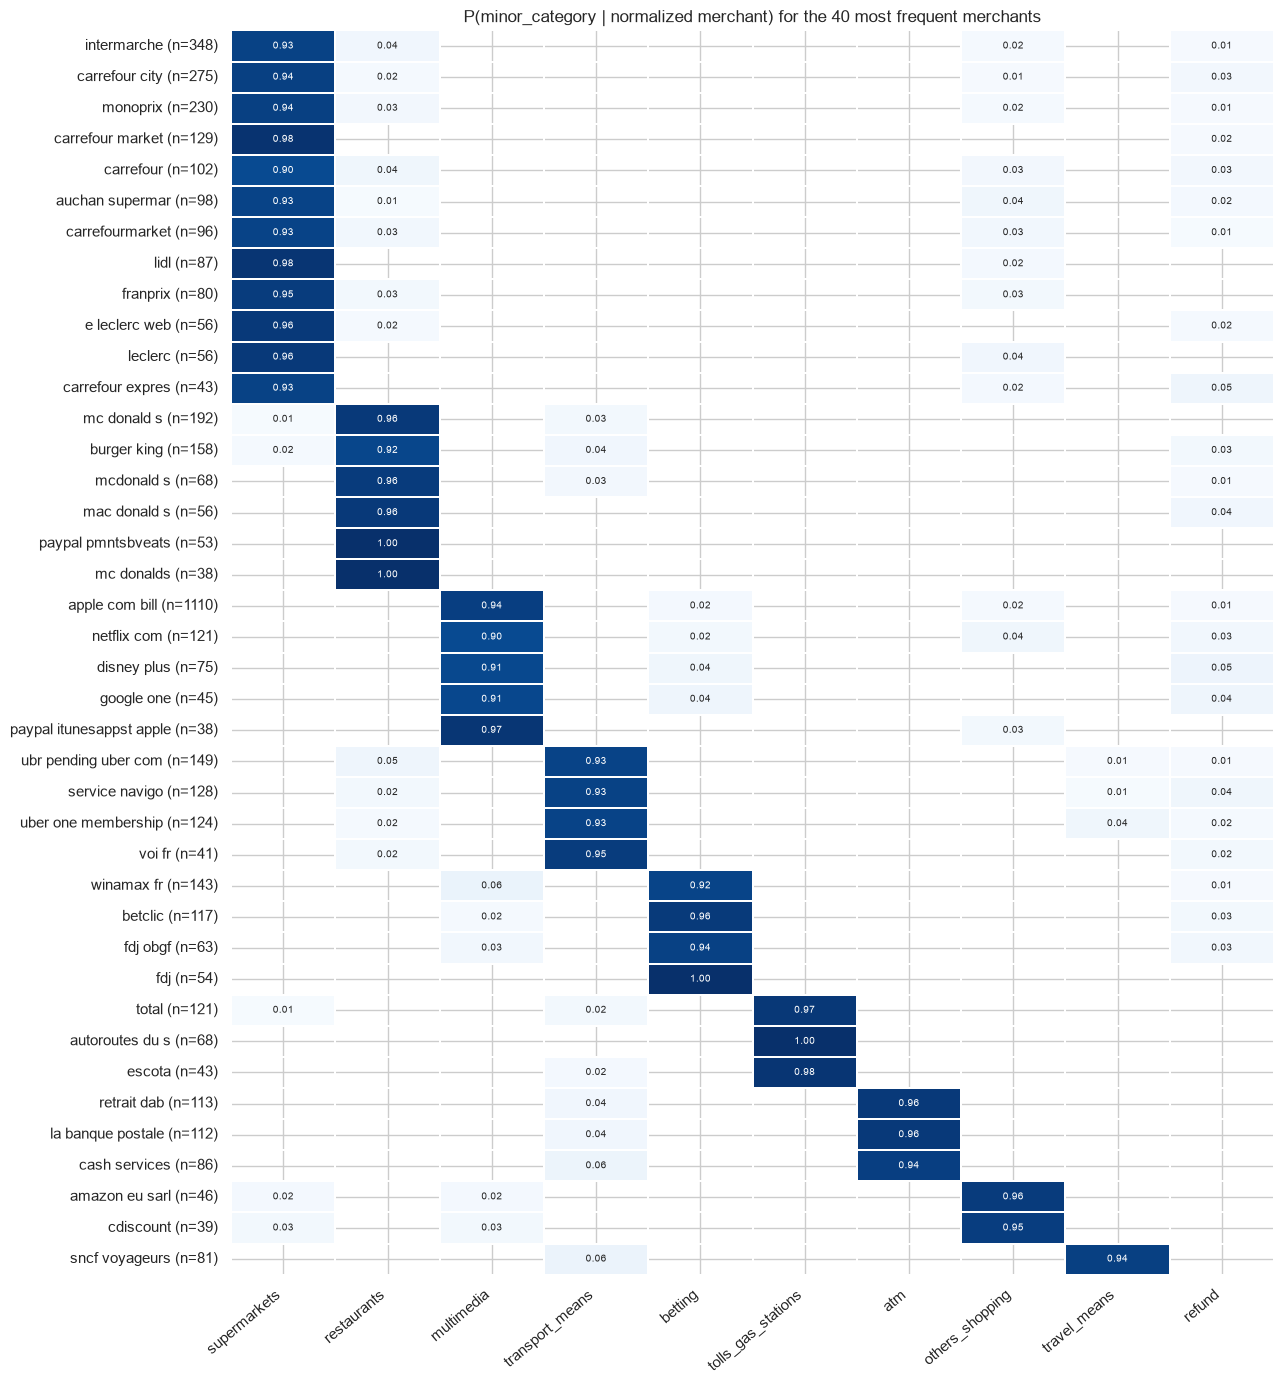

In [38]:
top = df["name_norm"].value_counts().head(40)
sub = df[df["name_norm"].isin(top.index)]
ct = pd.crosstab(sub["name_norm"], sub["minor_category"])
n = ct.sum(axis=1)
pct = ct.div(n, axis=0)

# order rows: by majority class (columns order), then by frequency
col_order = list(pct.sum().sort_values(ascending=False).index)
pct = pct[col_order]
maj_cls = pct.idxmax(axis=1)
row_order = sorted(pct.index, key=lambda m: (col_order.index(maj_cls[m]), -n[m]))
pct = pct.loc[row_order]
pct.index = [f"{m} (n={n[m]})" for m in row_order]

fig, ax = plt.subplots(figsize=(13, 14))
sns.heatmap(pct, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1,
            mask=(pct == 0), annot_kws={"size": 7}, ax=ax, linewidths=0.3, linecolor="white")
ax.set_title("P(minor_category | normalized merchant) for the 40 most frequent merchants")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

### 9.1 What separates the classes inside an ambiguous merchant?

In [39]:
top_amb = list(amb.index[:6])
for name in top_amb:
    sub = df[df["name_norm"] == name]
    print("=" * 100)
    print(f"{name!r}: {len(sub)} rows")
    prof = sub.groupby("minor_category").agg(
        n=("amount_value", "size"),
        amount_median=("abs_amount", "median"),
        amount_min=("abs_amount", "min"),
        amount_max=("abs_amount", "max"),
        positive_share=("amount_value", lambda s: (s > 0).mean()),
        entry_top=("merchant_pan_entry_method", lambda s: s.value_counts().index[0]),
        recurring_share=("pfm_recurring_frequency", lambda s: (s != "").mean()),
    ).round(2)
    display(prof)

'apple com bill': 1110 rows


,n,amount_median,amount_min,amount_max,positive_share,entry_top,recurring_share
minor_category,,,,,,,
betting,26,8.38,0.31,1082.66,0.0,CARD_ON_FILE,0.15
multimedia,1048,7.99,0.05,56475.30,0.0,CARD_ON_FILE,0.13
others_shopping,20,8.12,0.18,21533.52,0.0,CARD_ON_FILE,0.15
refund,16,6.99,0.31,16.34,1.0,CARD_ON_FILE,0.19


'intermarche': 348 rows


,n,amount_median,amount_min,amount_max,positive_share,entry_top,recurring_share
minor_category,,,,,,,
others_shopping,6,22.98,7.97,38.69,0.0,CHIP_CONTACTLESS,0.0
refund,5,3.53,1.45,22.90,1.0,CHIP_CONTACTLESS,0.0
restaurants,13,4.53,0.67,57.95,0.0,CHIP_CONTACTLESS,0.0
supermarkets,324,11.20,0.43,5187.32,0.0,CHIP_CONTACTLESS,0.0


'carrefour city': 275 rows


,n,amount_median,amount_min,amount_max,positive_share,entry_top,recurring_share
minor_category,,,,,,,
others_shopping,4,25.72,4.09,62.08,0.0,CHIP_CONTACTLESS,0.0
refund,8,15.62,2.14,30.89,1.0,CHIP_CONTACTLESS,0.0
restaurants,5,25.46,12.12,51.36,0.0,CHIP_CONTACTLESS,0.0
supermarkets,258,11.98,0.05,1958.44,0.0,CHIP_CONTACTLESS,0.0


... (2 outputs left out)

'mc donald s': 192 rows


,n,amount_median,amount_min,amount_max,positive_share,entry_top,recurring_share
minor_category,,,,,,,
restaurants,185,12.53,0.22,399180.56,0.0,CHIP_CONTACTLESS,0.0
supermarkets,2,18.65,16.23,21.07,0.0,CHIP,0.0
transport_means,5,13.80,4.31,32.29,0.0,CHIP_CONTACTLESS,0.0


'burger king': 158 rows


,n,amount_median,amount_min,amount_max,positive_share,entry_top,recurring_share
minor_category,,,,,,,
refund,4,36.36,4.92,86.59,1.0,CHIP_CONTACTLESS,0.0
restaurants,145,12.35,0.13,156572.69,0.0,CHIP_CONTACTLESS,0.0
supermarkets,3,15.35,6.33,330978.29,0.0,CHIP_CONTACTLESS,0.0
transport_means,6,12.93,4.13,54.82,0.0,CHIP_CONTACTLESS,0.0


> 📝 **NOTE (jafar):** here I assume we could make suggestion that some of the events were misclassified. We know for sure, that intermarche, monoprix, are supermarkets, and that mc donalds and burger kind are "restaurant". But we could also have, within intermarche for example, some cafeteria, in which case, it could be classified as "restaurant" as well. Need to investigate firther, but not now.

In [40]:
# raw (un-normalized) names of the ambiguous merchants: are the different classes explained by different spellings?
for name in top_amb[:4]:
    sub = df[df["name_norm"] == name]
    print(f"\n{name!r}: raw spelling x class")
    display(pd.crosstab(sub["text_raw"], sub["minor_category"]))


'apple com bill': raw spelling x class


minor_category,betting,multimedia,others_shopping,refund
text_raw,,,,
APPLE.COM/BILL,26,1048,20,16



'intermarche': raw spelling x class


minor_category,others_shopping,refund,restaurants,supermarkets
text_raw,,,,
INTERMARCHE,6,5,13,324



'carrefour city': raw spelling x class


minor_category,others_shopping,refund,restaurants,supermarkets
text_raw,,,,
CARREFOUR CITY,4,8,5,254
carrefour city,0,0,0,4



'monoprix': raw spelling x class


minor_category,others_shopping,refund,restaurants,supermarkets
text_raw,,,,
MONOPRIX,4,3,7,216


### 9.2 Label consistency: is there label noise?
Refunds are excluded here (they are fully identified by the amount sign). For every other row we compare its label with the
**majority label of its normalized merchant name**. If disagreements are spread uniformly (across amounts, entry methods, hours,
merchant sizes), they are probably noise rather than a learnable signal.

In [41]:
nr = df[df["minor_category"] != "refund"].copy()
maj = nr.groupby("name_norm")["minor_category"].agg(lambda s: s.value_counts().index[0])
nr["name_majority"] = nr["name_norm"].map(maj)
nr["disagrees"] = nr["minor_category"] != nr["name_majority"]
nr["name_n"] = nr["name_norm"].map(nr.groupby("name_norm").size())

print(f"non-refund rows disagreeing with their merchant's majority class: {int(nr['disagrees'].sum())} / {len(nr)} = {nr['disagrees'].mean():.2%}")
print("\ndisagreement rate by merchant size:")
display(nr.groupby(pd.cut(nr["name_n"], [0, 1, 5, 20, 100, 10_000]), observed=True)["disagrees"].agg(["mean", "size"]).round(3))
print("disagreement rate by |amount| bucket:")
display(nr.groupby(pd.cut(nr["abs_amount"], [-1, 100, 1000, 10_000, 1e9]), observed=True)["disagrees"].agg(["mean", "size"]).round(3))
print("disagreement rate by entry method:")
display(nr.groupby("merchant_pan_entry_method")["disagrees"].agg(["mean", "size"]).round(3))
print("disagreement rate by hour block:")
display(nr.groupby(pd.cut(nr["hour"], [-1, 5, 11, 17, 23]), observed=True)["disagrees"].agg(["mean", "size"]).round(3))
print("most frequent (merchant majority class -> actual label) flips:")
display(nr[nr["disagrees"]].groupby(["name_majority", "minor_category"]).size().sort_values(ascending=False).head(12).to_frame("n"))

non-refund rows disagreeing with their merchant's majority class: 312 / 7998 = 3.90%

disagreement rate by merchant size:


,mean,size
name_n,,
"(0, 1]",0.000,375
"(1, 5]",0.035,1128
"(5, 20]",0.046,993
"(20, 100]",0.037,1988
"(100, 10000]",0.043,3514


disagreement rate by |amount| bucket:


,mean,size
abs_amount,,
"(-1.0, 100.0]",0.039,7546
"(100.0, 1000.0]",0.041,269
"(1000.0, 10000.0]",0.034,119
"(10000.0, 1000000000.0]",0.031,64


disagreement rate by entry method:


,mean,size
merchant_pan_entry_method,,
CARD_ON_FILE,0.043,2236
CHIP,0.042,841
CHIP_CONTACTLESS,0.036,4028
CHIP_FALLBACK,0.111,9
MAG_STRIPE,0.000,3
MANUAL,0.039,880
none,0.000,1


disagreement rate by hour block:


,mean,size
hour,,
"(-1, 5]",0.037,979
"(5, 11]",0.040,1549
"(11, 17]",0.040,2898
"(17, 23]",0.038,2572


most frequent (merchant majority class -> actual label) flips:


n
name_majority      minor_category     
supermarkets       restaurants      52
                   others_shopping  48
multimedia         betting          38
                   others_shopping  30
restaurants        transport_means  28
transport_means    restaurants      21
restaurants        supermarkets     16
betting            multimedia       14
transport_means    travel_means     14
atm                transport_means  13
travel_means       transport_means   9
tolls_gas_stations supermarkets      7

> 📝 **NOTE (jafar):** we can see some common flipping, like betting -> mulimedia and vice versa, or restaurants -> transport means, and vice versa. I assume the later is caused by delivery companies, delivering from restaurant, not sure yet how to handle this, need further investigation, for now, let the model find the patterns (and check later). Supermarkets and restaurants as well, same situation (restaurant in supermarket can be the cause).

Note: for merchants seen exactly once, a "majority" is the row's own label so disagreement is 0 by construction; that is why the
rate is reported by merchant size.

## 10. Duplicates, identifiers and leakage risks
### 10.1 `ref_id` duplicates

> 📝 **NOTE (jafar):** We definitely dont need ref_id, this is unlikely to bring any value. Same as members and merchant ids. (members id should be excluded, as it might include bias in the model). 

In [42]:
print("transaction_id duplicated:", int(df["transaction_id"].duplicated().sum()))
dup = df[df["ref_id"].duplicated(keep=False)].sort_values(["ref_id", "transaction_id"])
print("ref_id: rows involved in a duplicate:", len(dup), "| distinct duplicated ref_ids:", dup["ref_id"].nunique())
print("sizes of duplicate groups:", dup.groupby("ref_id").size().value_counts().to_dict())

# which columns differ inside a duplicated ref_id group?
cols = [c for c in df.columns if c in pd.read_csv(DATA_PATH, nrows=0).columns and c not in ("ref_id",)]
differs = {c: int((dup.groupby("ref_id")[c].nunique() > 1).sum()) for c in cols}
print("\nnumber of duplicate groups where each column differs:")
display(pd.Series(differs, name="groups_where_it_differs").to_frame().T)

transaction_id duplicated: 0
ref_id: rows involved in a duplicate: 240 | distinct duplicated ref_ids: 120
sizes of duplicate groups: {2: 120}

number of duplicate groups where each column differs:


,transaction_id,created_at,member_id,member_name,merchant_id,merchant_name,title,amount_value,amount_currency,fees,card_type,card_name,digitalization_type,merchant_pan_entry_method,pfm_recurring_frequency,status,major_category,minor_category
groups_where_it_differs,120,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [43]:
display(dup.head(6)[["transaction_id", "ref_id", "created_at", "member_id", "merchant_name", "amount_value", "merchant_pan_entry_method", "minor_category"]])

,transaction_id,ref_id,created_at,member_id,merchant_name,amount_value,merchant_pan_entry_method,minor_category
4718,10018044,06ffb4a9675aa8ae,2026-03-26 13:53:50+00:00,21267237,MCDONALD S,-7.84,CHIP_CONTACTLESS,restaurants
3584,10032055,06ffb4a9675aa8ae,2026-03-26 13:53:50+00:00,21267237,MCDONALD S,-7.84,CHIP_CONTACTLESS,restaurants
6762,10010479,075b95d9889fcd29,2026-06-08 19:43:43+00:00,47376585,INTERMARCHE,-35.90,CHIP_CONTACTLESS,supermarkets
3873,10032228,075b95d9889fcd29,2026-06-08 19:43:43+00:00,47376585,INTERMARCHE,-35.90,CHIP_CONTACTLESS,supermarkets
6044,10001019,07917130bcfebd92,2026-03-19 04:57:06+00:00,90967191,NETFLIX.COM,0.41,CARD_ON_FILE,refund
1808,10032260,07917130bcfebd92,2026-03-19 04:57:06+00:00,90967191,NETFLIX.COM,0.41,CARD_ON_FILE,refund


In [44]:
# also: duplicate rows ignoring transaction_id / ref_id? (same member, merchant, time, amount)
key = ["member_id", "merchant_id", "created_at", "amount_value"]
print("rows duplicated on (member, merchant, created_at, amount):", int(df.duplicated(subset=key, keep=False).sum()))
print("created_at duplicates:", int(df["created_at"].duplicated().sum()))

rows duplicated on (member, merchant, created_at, amount): 240
created_at duplicates: 122


### 10.2 Members and merchant ids

In [45]:
per_member = df.groupby("member_id").size()
print("members:", len(per_member), "| transactions per member: median", per_member.median(), ", max", per_member.max())
print("members with exactly 1 transaction:", int((per_member == 1).sum()))

mem_names = df.groupby("member_id")["member_name"].nunique()
print("member_ids with >1 member_name:", int((mem_names > 1).sum()))
name_ids = df.groupby("member_name")["member_id"].nunique()
print("member_names shared by several member_ids:", int((name_ids > 1).sum()), "(names are synthetic and not unique)")

mid = df.groupby("merchant_id")["name_norm"].nunique()
print("\nmerchant_ids:", df["merchant_id"].nunique(), "| merchant_ids mapping to >1 normalized name:", int((mid > 1).sum()))
per_name_ids = df.groupby("name_norm")["merchant_id"].nunique()
print("normalized names with >1 merchant_id (one id per point of sale?):", int((per_name_ids > 1).sum()))
print("rows per merchant_id: median", df.groupby("merchant_id").size().median())
mid_cls = df.groupby("merchant_id")["minor_category"].nunique()
print("merchant_ids with >1 minor class:", int((mid_cls > 1).sum()))

members: 2395 | transactions per member: median 3.0 , max 11
members with exactly 1 transaction: 292
member_ids with >1 member_name: 0
member_names shared by several member_ids: 676 (names are synthetic and not unique)

merchant_ids: 2789 | merchant_ids mapping to >1 normalized name: 0
normalized names with >1 merchant_id (one id per point of sale?): 510
rows per merchant_id: median 1.0
merchant_ids with >1 minor class: 227


### 10.3 Do member / merchant ids generalize?
A feature is only useful at prediction time if its values will mostly be **seen at training time**. We approximate this with a quick
simulation: randomly split rows 80/20 and measure how many validation rows have an id never seen in the other 80%. (This is only a diagnostic
of coverage, not the modeling split, which is still to be decided.)

In [46]:
rng = np.random.default_rng(0)
mask = rng.random(len(df)) < 0.8
tr, va = df[mask], df[~mask]
for col in ["member_id", "merchant_id", "name_norm", "text_raw"]:
    unseen = (~va[col].isin(set(tr[col]))).mean()
    print(f"{col:12s}: {unseen:.1%} of validation rows have a value never seen in the training part")

member_id   : 7.0% of validation rows have a value never seen in the training part
merchant_id : 24.8% of validation rows have a value never seen in the training part
name_norm   : 5.3% of validation rows have a value never seen in the training part
text_raw    : 5.4% of validation rows have a value never seen in the training part


## 11. Feature-target association (summary view)

Bias-corrected **Cramer's V** between each candidate feature and `minor_category` (0 = independent, 1 = perfectly determined).
High-cardinality features (names, ids) are naturally inflated even after correction, so they are flagged separately.

,cramers_v,n_unique,high_cardinality
status,0.999,2,False
name_norm,0.842,930,True
merchant_id,0.724,2789,True
amount_sign,0.711,3,False
merchant_pan_entry_method,0.490,7,False
pfm_recurring_frequency,0.289,2,False
digitalization_type,0.175,14,False
amount_bin (deciles of |amount|),0.172,10,False
hour,0.137,24,False
member_id,0.065,2395,True


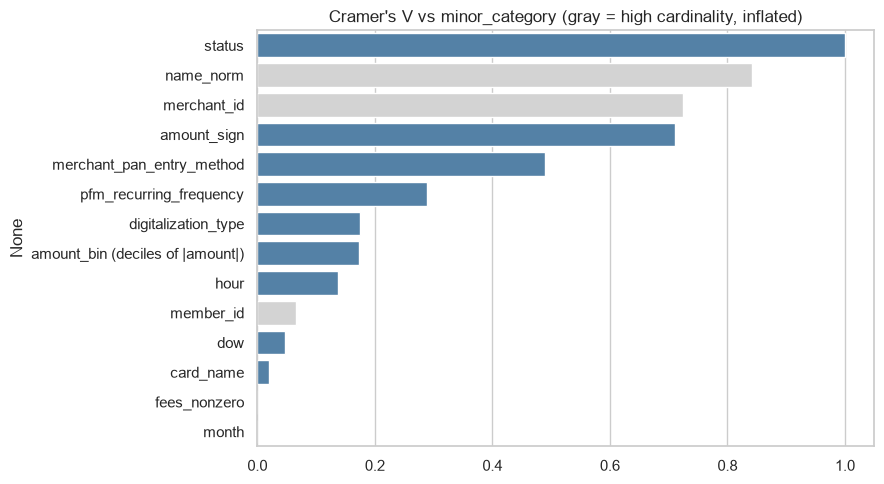

In [47]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rcorr = r - (r - 1) ** 2 / (n - 1)
    kcorr = k - (k - 1) ** 2 / (n - 1)
    denom = min(kcorr - 1, rcorr - 1)
    return float(np.sqrt(phi2 / denom)) if denom > 0 else np.nan

feat = pd.DataFrame({
    "name_norm": df["name_norm"],
    "merchant_id": df["merchant_id"],
    "member_id": df["member_id"],
    "amount_sign": df["amount_sign"],
    "amount_bin (deciles of |amount|)": pd.qcut(df["abs_amount"], 10, duplicates="drop").astype(str),
    "merchant_pan_entry_method": df["merchant_pan_entry_method"],
    "digitalization_type": df["digitalization_type"],
    "card_name": df["card_name"],
    "pfm_recurring_frequency": df["pfm_recurring_frequency"],
    "fees_nonzero": df["fees_nonzero"].astype(str),
    "status": df["status"],
    "hour": df["hour"].astype(str),
    "dow": df["dow"].astype(str),
    "month": df["month"].astype(str),
})
high_card = {"name_norm", "merchant_id", "member_id"}
res = pd.Series({c: cramers_v(feat[c], df["minor_category"]) for c in feat.columns}).sort_values(ascending=False)
res_df = res.to_frame("cramers_v").assign(n_unique=[feat[c].nunique() for c in res.index],
                                             high_cardinality=[c in high_card for c in res.index]).round(3)
display(res_df)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=res.values, y=res.index, ax=ax, hue=[c in high_card for c in res.index], palette={True: "lightgray", False: "steelblue"}, legend=False)
ax.set_title("Cramer's V vs minor_category (gray = high cardinality, inflated)")
plt.tight_layout(); plt.show()

> 📝 **NOTE (jafar):** we can see some high correlation with some of the features. Status, as I remember is only different in case of refunded, (only two values), to be exluded. The months, no correlation, not enough data, (only few months of data). merchant id, we said we remove. member id as well. 

## 12. Summary of findings and modeling implications

**Data and labels**
- 8,121 rows, 19 columns, 2026-03-13 to 2026-06-10 (about 3 months; March and June are partial months). No NaN, only `''` strings.
- Labels are clean strings (no case or whitespace variants). `minor_category` is imbalanced (20x between `supermarkets` and `hairdresser`).
- **Strict hierarchy**: each minor class maps to exactly one major class, except `refund`, whose `major_category` is **empty** for all 123 rows.
  *Decision needed*: extra `refund` / `none` class for major, or derive major from minor.
- **`refund` is solved by the amount sign**: all 123 refunds are the only positive amounts. `status == 'refunded'` coincides exactly (Cramer's V = 0.999),
  but it is probably not known at transaction time, so we should rely on the sign and not on `status`.
- **`atm`** is not identifiable from the sign (negative), but is very distinctive: empty `merchant_name` (title `RETRAIT DAB`) or bank-like names,
  numeric terminal ids, entry method `CHIP`, round amounts. Five ATM rows have amount `-0.0`.

**Columns**
- Drop: `card_type`, `amount_currency` (constant), `fees` (V = 0), `month` (V = 0, partial months), `member_*` and `*_id` identifiers (do not generalize: 25% of
  `merchant_id` values are unseen in a random 80/20 split, vs 5% for the normalized merchant name), `card_name` (30 values that are mostly FR/EN variants of the same cards, V = 0.02), `status`.
- `title` equals `merchant_name` except in 113 rows (empty `merchant_name`, mostly ATM): build one text field with a fallback, plus an "empty name" flag.
- Keep: merchant text, amount sign, log |amount|, entry method, `digitalization_type` (14 values; besides wallets it holds token requestors such as UBER, SPOTIFY, PAYPAL, NETFLIX, which are merchant-specific), `pfm_recurring_frequency` flag, hour of day (plausible lunch / evening peaks, V = 0.14), weekday (weak).
- **Amounts contain implausible outliers**: 65 rows above EUR 10,000 (mostly `restaurants` and `multimedia`; 21 above EUR 100,000). Use log scale, clipping, or tree models, and do not trust raw magnitude.

**Merchant names**
- 960 raw names become 930 after deterministic cleaning. Long tail: 40% of merchants appear once (but only 4.6% of rows); the top 100 cover 76% of rows.
- Levenshtein clustering at similarity 0.85 gives 867 clusters from 930 names: a modest reduction, with a few bad merges (e.g. names that differ by a store number). It is
  worth testing as a feature, but character n-gram TF-IDF may already capture the same information.

**Ambiguity, noise and ceiling**
- 145 normalized names (15.6%) carry more than one label, covering 72% of the rows, but mostly because of a few deviating rows in very frequent merchants (e.g. `apple.com/bill`: 1,048 multimedia, 26 betting, 20 others_shopping, 16 refund).
- Excluding refunds, **3.9% of rows (312) contradict the majority label of their merchant**, at a roughly flat rate (3 to 4%) across amount, entry method, hour and merchant size.
  This pattern is consistent with **label noise** (e.g. McDonald's labeled `transport_means`), not a learnable signal. For `apple.com/bill`, amounts and entry methods look the same across its different labels.
- A pure in-sample lookup on the normalized name gives 94.7% accuracy; adding the amount sign (which resolves refunds) gives 96.2%. **A realistic accuracy ceiling is about 96%**.
  Scores far above it would suggest that the model memorizes noise or that there is leakage.

**Duplicates**
- 120 `ref_id` values appear twice, and these pairs are **exact duplicates** (all columns identical except `transaction_id`). They must be removed (or grouped) before
  splitting; otherwise a copy lands in train and its twin in validation, which inflates the metrics.

**Implications for the next step**
1. Deduplicate on `ref_id`; build `text = merchant_name or title`; normalized name; empty-name flag.
2. Primary metric: macro-F1 plus per-class report (imbalance); accuracy only as a secondary metric, interpreted against the ~96% ceiling.
3. Baseline: TF-IDF (character n-grams) on the normalized name + logistic regression, then add the structured features, then compare tree models.
4. Splitting strategy is still open: random stratified (primary), plus a "merchant-grouped" evaluation to measure behaviour on unseen merchants (5% of rows in a random split).
5. Decide how to handle major for `refund` and whether to model minor-only, both, or hierarchically.

> 📝 **NOTE (jafar):** why to remove card name? might carry info, agree that it has fr / eng duplicates, need to be cleaned, so we can remove now, but keep in mind and clean and add later. Regarding outliers, lets start with tree based model (xgboost). 